Starting data acquisition...
Successfully scraped 200 books!

Cleaning data...
Cleaned Dataset Sample:
                                   Title  Price_GBP  Rating_Num  In_Stock
0                   A Light in the Attic      51.77           3         1
1                     Tipping the Velvet      53.74           1         1
2                             Soumission      50.10           1         1
3                          Sharp Objects      47.82           4         1
4  Sapiens: A Brief History of Humankind      54.23           5         1

Dataset successfully saved as 'cleaned_books_dataset.csv'!

Generating visualisations...


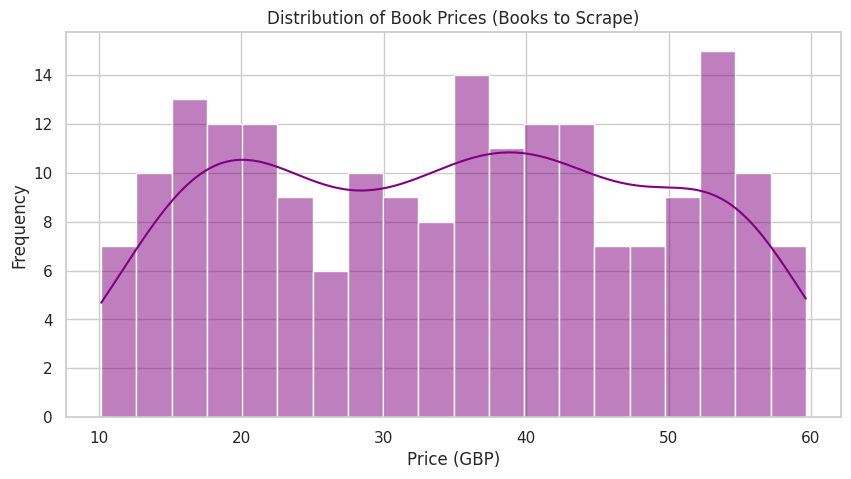

/tmp/ipykernel_1092/669418337.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Rating_Num', y='Price_GBP', data=df_clean, palette='Set2')


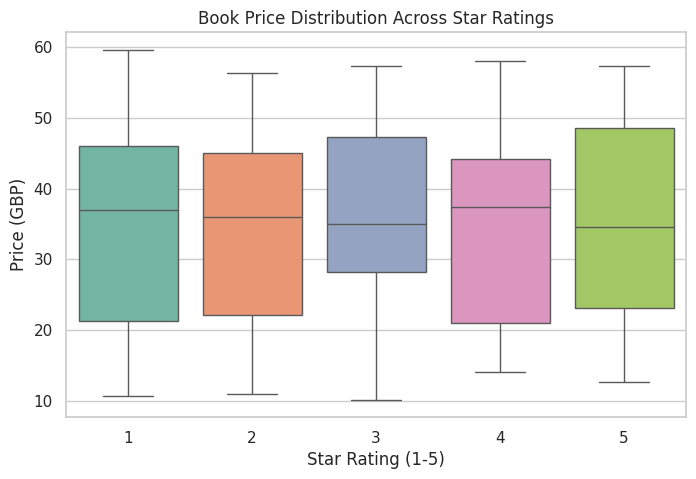


Running Linear Regression Model...

--- Model Evaluation Results ---
Coefficients: [0.25584102 0.        ]
Intercept: 33.80
Mean Squared Error (MSE): 232.73
R-squared Score (R2): -0.01


In [3]:

# 1. DATA ACQUISITION (WEB SCRAPING)

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Starting data acquisition...")

# Base URL for Books to Scrape website
base_url = "http://books.toscrape.com/catalogue/page-{}.html"
books_data = []

# Scrape the first 10 pages (20 books per page = 200 books total, satisfying the minimum requirement)[cite: 3]
for page in range(1, 11):
    url = base_url.format(page)
    response = requests.get(url)
    if response.status_code != 200:
        break

    soup = BeautifulSoup(response.text, 'html.parser')
    books = soup.find_all('article', class_='product_pod')

    for book in books:
        # Extract Title
        title = book.find('h3').find('a')['title']

        # Extract Price string (e.g., '£51.77')
        price_str = book.find('p', class_='price_color').text

        # Extract Star Rating word (e.g., 'Three', 'Five')
        rating_tag = book.find('p', class_='star-rating')
        rating_word = rating_tag['class'][1] if rating_tag else 'Unknown'

        # Extract Availability status
        availability = book.find('p', class_='instock availability').text.strip()

        books_data.append({
            'Title': title,
            'Raw_Price': price_str,
            'Rating_Word': rating_word,
            'Availability': availability
        })

df_raw = pd.DataFrame(books_data)
print(f"Successfully scraped {len(df_raw)} books!")



# 2. DATA CLEANING & PREPARATION

print("\nCleaning data...")
df = df_raw.copy()

# Clean Price: Remove currency symbols and convert to float for numeric operations
df['Price_GBP'] = df['Raw_Price'].str.replace('Â£', '').str.replace('£', '').astype(float)

# Map text ratings to numeric integers (1 to 5)
rating_map = {
    'One': 1,
    'Two': 2,
    'Three': 3,
    'Four': 4,
    'Five': 5
}
df['Rating_Num'] = df['Rating_Word'].map(rating_map).fillna(0).astype(int)

# Clean Availability: Create a binary numeric indicator (1 = In stock, 0 = Out of stock)
df['In_Stock'] = df['Availability'].apply(lambda x: 1 if 'In stock' in x else 0)

# Create final clean dataset structure
df_clean = df[['Title', 'Price_GBP', 'Rating_Num', 'In_Stock']].dropna()

print("Cleaned Dataset Sample:")
print(df_clean.head())

# Save your final dataset to a CSV file (Deliverable 2 requirement)
df_clean.to_csv('cleaned_books_dataset.csv', index=False)
print("\nDataset successfully saved as 'cleaned_books_dataset.csv'!")



# 3. DATA VISUALIZATION & EXPLORATION

print("\nGenerating visualisations...")
sns.set_theme(style="whitegrid")

# Plot 1: Histogram of Book Prices
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['Price_GBP'], bins=20, kde=True, color='purple')
plt.title('Distribution of Book Prices (Books to Scrape)')
plt.xlabel('Price (GBP)')
plt.ylabel('Frequency')
plt.show()

# Plot 2: Boxplot comparing Star Ratings vs Price
plt.figure(figsize=(8, 5))
sns.boxplot(x='Rating_Num', y='Price_GBP', data=df_clean, palette='Set2')
plt.title('Book Price Distribution Across Star Ratings')
plt.xlabel('Star Rating (1-5)')
plt.ylabel('Price (GBP)')
plt.show()



# 4. PREDICTIVE MODELLING (LINEAR REGRESSION)

print("\nRunning Linear Regression Model...")

# Select features (X) and target variable (y)
X = df_clean[['Rating_Num', 'In_Stock']]
y = df_clean['Price_GBP']

# Split data into training set (80%) and testing set (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

# Evaluate model performance
print("\n--- Model Evaluation Results ---")
print(f"Coefficients: {model.coef_}")
print(f"Intercept: {model.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.2f}")
print(f"R-squared Score (R2): {r2_score(y_test, y_pred):.2f}")